# Boston Housing Price Prediction — End-to-End ML Workflow

This notebook demonstrates a **reproducible educational regression workflow** on a modified historical Boston Housing dataset (489 rows, 3 predictors). The completed notebook includes EDA, holdout split, baseline, model comparison, learning curves, cross-validation, hyperparameter tuning and final evaluation.

> **Dataset provenance and ethics:** This 489-row dataset follows the modified Boston Housing educational exercise popularized by Udacity; it excludes capped/outlier records and scales `MEDV` for a historical inflation adjustment. The underlying data is old and `LSTAT` is a problematic socioeconomic proxy. Do not interpret these predictions as current property appraisals or deploy this model in high-stakes pricing decisions. See [MODEL_CARD.md](docs/MODEL_CARD.md).

**How to run:** Start Jupyter from the repository root, then open this notebook and run all cells. The notebook loads `housing.csv` and `visuals.py` from the same repository. The final cell exports `boston_rf_model.joblib` (overwriting the committed copy if run).


## 1. Problem Understanding

This is a supervised learning problem because the dataset includes both input features and a known target value.
It is a regression problem because the goal is to predict a continuous value: the median home value, `MEDV`.

The features are:

| Feature | Meaning |
| --- | --- |
| `RM` | Average number of rooms per home |
| `LSTAT` | Percentage of lower-status population |
| `PTRATIO` | Student-to-teacher ratio |

The goal is to train a model that predicts `MEDV` as accurately as possible for unseen homes.


## 2. Import Libraries and Load Data


In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import visuals as vs

from joblib import parallel_backend
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, learning_curve, train_test_split
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")


In [3]:
df = pd.read_csv("housing.csv")
df.head()


,RM,LSTAT,PTRATIO,MEDV
0,6.575,4.98,15.3,504000.0
1,6.421,9.14,17.8,453600.0
2,7.185,4.03,17.8,728700.0
3,6.998,2.94,18.7,701400.0
4,7.147,5.33,18.7,760200.0


## 3. Data Understanding / EDA

The first checks show the dataset size, column types, missing values, and descriptive statistics.


In [4]:
df.shape


(489, 4)

In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 489 entries, 0 to 488
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   RM       489 non-null    float64
 1   LSTAT    489 non-null    float64
 2   PTRATIO  489 non-null    float64
 3   MEDV     489 non-null    float64
dtypes: float64(4)
memory usage: 15.4 KB


In [6]:
df.isnull().sum()


RM         0
LSTAT      0
PTRATIO    0
MEDV       0
dtype: int64

In [7]:
df.describe()


,RM,LSTAT,PTRATIO,MEDV
count,489.000000,489.000000,489.000000,4.890000e+02
mean,6.240288,12.939632,18.516564,4.543429e+05
std,0.643650,7.081990,2.111268,1.653403e+05
min,3.561000,1.980000,12.600000,1.050000e+05
25%,5.880000,7.370000,17.400000,3.507000e+05
50%,6.185000,11.690000,19.100000,4.389000e+05
75%,6.575000,17.120000,20.200000,5.187000e+05
max,8.398000,37.970000,22.000000,1.024800e+06


The dataset contains 489 rows and 4 columns: `RM`, `LSTAT`, `PTRATIO`, and `MEDV`.
All columns are numeric `float64` values, and there are no missing values.

The scientific notation shown in the descriptive statistics, such as `4.543429e+05`, is display formatting only.
It means `454,342.9`; it is not a datatype problem and does not require converting the columns.


In [8]:
price_statistics = pd.Series(
    {
        "Minimum price": df["MEDV"].min(),
        "Maximum price": df["MEDV"].max(),
        "Mean price": df["MEDV"].mean(),
        "Median price": df["MEDV"].median(),
        "Standard deviation": df["MEDV"].std(),
    },
    name="MEDV",
)

price_statistics.map(lambda value: f"${value:,.2f}")


Minimum price           $105,000.00
Maximum price         $1,024,800.00
Mean price              $454,342.94
Median price            $438,900.00
Standard deviation      $165,340.28
Name: MEDV, dtype: object

The target prices range from about $105,000 to about $1,024,800, with an average around $454,343.
These statistics provide useful context for later model predictions.


## 4. Data Cleaning

### Missing Values

There are no missing values in the dataset.


In [9]:
df.isnull().sum()


RM         0
LSTAT      0
PTRATIO    0
MEDV       0
dtype: int64

### Duplicates


In [10]:
df.duplicated().sum()


np.int64(0)

There are no duplicated rows.

### Data Types


In [11]:
df.dtypes


RM         float64
LSTAT      float64
PTRATIO    float64
MEDV       float64
dtype: object

All variables already have appropriate numeric data types for modeling.


### Outliers

The boxplots and IQR summaries below identify statistical outliers. These values should be inspected, but not automatically removed.


In [12]:
fig = px.box(
    df,
    y="MEDV",
    points="outliers",
    title="MEDV Boxplot",
)
fig.show()


In [13]:
fig = px.box(
    df,
    y=["RM", "LSTAT", "PTRATIO"],
    points="outliers",
    title="Feature Boxplots",
)
fig.show()


In [14]:
outlier_summary = []

for column in df.columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = df[(df[column] < lower_bound) | (df[column] > upper_bound)].shape[0]

    outlier_summary.append(
        {
            "Feature": column,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Lower Bound": lower_bound,
            "Upper Bound": upper_bound,
            "Outlier Count": outlier_count,
        }
    )

outlier_summary = pd.DataFrame(outlier_summary)
outlier_summary


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,RM,5.88,6.575,0.695,4.8375,7.6175,22
1,LSTAT,7.37,17.120,9.750,-7.2550,31.7450,7
2,PTRATIO,17.40,20.200,2.800,13.2000,24.4000,13
3,MEDV,350700.00,518700.000,168000.000,98700.0000,770700.0000,22


In [15]:
medv_bounds = outlier_summary.loc[outlier_summary["Feature"] == "MEDV"].iloc[0]
medv_outliers = df[
    (df["MEDV"] < medv_bounds["Lower Bound"])
    | (df["MEDV"] > medv_bounds["Upper Bound"])
]

medv_outliers.head()


,RM,LSTAT,PTRATIO,MEDV
97,8.069,4.21,18.0,812700.0
98,7.820,3.57,18.0,919800.0
157,6.943,4.59,14.7,867300.0
175,6.980,5.04,17.8,781200.0
176,7.765,7.56,17.8,835800.0


Statistical outliers are present in `MEDV`, `RM`, `LSTAT`, and `PTRATIO`.
However, an outlier does not necessarily mean an error.
The high `MEDV` values represent expensive homes that are plausible within the data range, and the feature outliers also appear to be valid observations.
There is no evidence that these values are data-entry mistakes, so the outliers are retained for modeling.


## 5. Features and Target


In [16]:
prices = df["MEDV"]
features = df.drop("MEDV", axis=1)

X = features
y = prices

print("features shape:", features.shape)
print("prices shape:", prices.shape)


features shape: (489, 3)
prices shape: (489,)


`features.shape` is `(489, 3)` because `features` is a DataFrame with 489 rows and 3 predictor columns.
`prices.shape` is `(489,)` because `prices` is a one-dimensional pandas Series containing only the target values.


## 6. Feature-Target Relationship Analysis

Correlation and scatter plots help show how each feature is related to the target.


In [17]:
correlation_matrix = df.corr()
correlation_matrix


,RM,LSTAT,PTRATIO,MEDV
RM,1.000000,-0.612033,-0.304559,0.697209
LSTAT,-0.612033,1.000000,0.360445,-0.760670
PTRATIO,-0.304559,0.360445,1.000000,-0.519034
MEDV,0.697209,-0.760670,-0.519034,1.000000


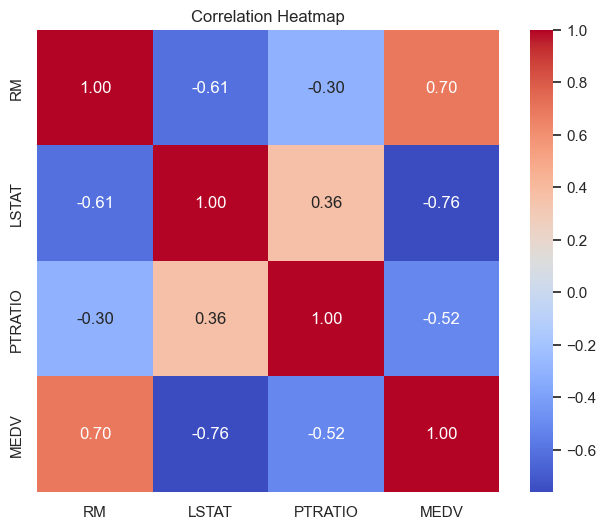

In [18]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True,
)
plt.title("Correlation Heatmap")
plt.show()


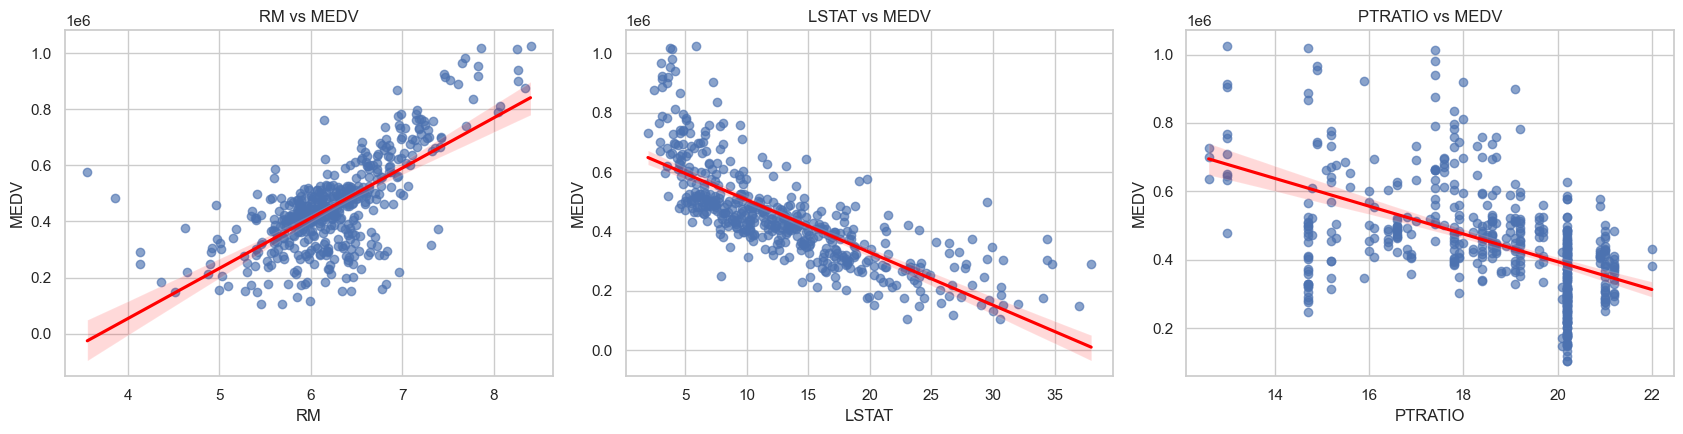

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, feature_name in zip(axes, ["RM", "LSTAT", "PTRATIO"]):
    sns.regplot(
        data=df,
        x=feature_name,
        y="MEDV",
        ax=ax,
        scatter_kws={"alpha": 0.65},
        line_kws={"color": "red"},
    )
    ax.set_title(f"{feature_name} vs MEDV")

plt.tight_layout()
plt.show()


`RM` has a positive relationship with `MEDV`: homes with more rooms tend to have higher prices.
`LSTAT` has the strongest negative relationship with `MEDV`.
`PTRATIO` has a moderate negative relationship with `MEDV`.

Correlation is useful for identifying relationships, but correlation does not imply causation.


## Question 1 - Feature Observation

Using intuition, for each of the three features `RM`, `LSTAT`, and `PTRATIO`, would an increase in that feature generally increase or decrease `MEDV`?

### Answer

`RM`: An increase in `RM` generally increases `MEDV` because homes with more rooms are usually larger and more valuable.

`LSTAT`: An increase in `LSTAT` generally decreases `MEDV` because higher lower-status population percentages are associated with lower housing values in this dataset.

`PTRATIO`: An increase in `PTRATIO` generally decreases `MEDV` because a higher student-to-teacher ratio may make an area less attractive to buyers.

### Observation from the Data

| Relationship | Correlation |
| --- | ---: |
| `RM` vs `MEDV` | +0.70 |
| `LSTAT` vs `MEDV` | -0.76 |
| `PTRATIO` vs `MEDV` | -0.52 |


## 7. Evaluation Metric

The main evaluation metric is the coefficient of determination, R^2.

R^2 = 1 means perfect predictions.
R^2 = 0 means the model is roughly no better than predicting the target mean.
R^2 < 0 means the model is worse than that mean-prediction baseline.

R^2 is a regression score, not classification accuracy.


In [20]:
def performance_metric(y_test, y_predict):
    return r2_score(y_test, y_predict)


In [21]:
example_actual = [3, -0.5, 2, 7, 4.2]
example_predicted = [2.5, 0.0, 2.1, 7.8, 5.3]

example_score = performance_metric(example_actual, example_predicted)
print(f"Model has a coefficient of determination, R^2, of {example_score:.3f}.")


Model has a coefficient of determination, R^2, of 0.923.


## Question 2 - Goodness of Fit

Would you consider this example model to have successfully captured the variation of the target variable? Why or why not?

### Answer

Yes. For this example, the model captures the target variation well because R^2 is about 0.923.
That means approximately 92.3% of the variation in those target values is explained by the predictions.


## 8. Train / Validation / Test Split

The dataset is split into development data and a held-out test set first.
The development data is then split again into training and validation data.


In [22]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    features,
    prices,
    test_size=0.2,
    random_state=1,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    random_state=1,
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)
print()
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)


X_train: (312, 3)
X_val: (79, 3)
X_test: (98, 3)

y_train: (312,)
y_val: (79,)
y_test: (98,)


Training data is used to fit model parameters.
Validation data is used during model comparison and development.
The test set is kept untouched until the final evaluation.

Repeatedly making decisions based on the test set would cause data leakage and test-set overfitting, making the final performance estimate too optimistic.


## Question 3 - Training and Testing

What is the benefit of splitting a dataset into training and testing subsets?

### Answer

Splitting the dataset lets the model learn from one subset and then be evaluated on unseen data.
This gives a better estimate of how well the model generalizes and helps reveal overfitting.
If a model performs very well on the training data but poorly on unseen data, it is likely fitting noise or overly specific patterns from the training set.


## 9. Baseline Model

A baseline provides a simple benchmark.
Here, the baseline always predicts the mean target value from the training set.
Real machine learning models should clearly outperform this naive prediction.


In [23]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

train_pred_baseline = baseline.predict(X_train)
val_pred_baseline = baseline.predict(X_val)

train_r2_baseline = performance_metric(y_train, train_pred_baseline)
val_r2_baseline = performance_metric(y_val, val_pred_baseline)

print(f"Baseline Train R^2: {train_r2_baseline:.3f}")
print(f"Baseline Validation R^2: {val_r2_baseline:.3f}")


Baseline Train R^2: 0.000
Baseline Validation R^2: -0.015


The training R^2 is 0 because the baseline predicts the training-set mean.
The validation R^2 is slightly negative because the training-set mean is not exactly the same as the validation-set mean.


## 10. Initial Regression Models

The next models are trained on the training set and compared on the validation set.


### Linear Regression


In [24]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

train_pred_linear = linear_model.predict(X_train)
val_pred_linear = linear_model.predict(X_val)

train_r2_linear = performance_metric(y_train, train_pred_linear)
val_r2_linear = performance_metric(y_val, val_pred_linear)

print(f"Linear Regression Train R^2: {train_r2_linear:.3f}")
print(f"Linear Regression Validation R^2: {val_r2_linear:.3f}")


Linear Regression Train R^2: 0.719
Linear Regression Validation R^2: 0.706


The train and validation scores are close, so there is little obvious overfitting.
However, performance is limited compared with stronger nonlinear models, suggesting that the relationships are not fully captured by a simple linear model.


### Decision Tree Regressor


In [25]:
tree_model = DecisionTreeRegressor(random_state=1)
tree_model.fit(X_train, y_train)

train_pred_tree = tree_model.predict(X_train)
val_pred_tree = tree_model.predict(X_val)

train_r2_tree = performance_metric(y_train, train_pred_tree)
val_r2_tree = performance_metric(y_val, val_pred_tree)

print(f"Decision Tree Train R^2: {train_r2_tree:.3f}")
print(f"Decision Tree Validation R^2: {val_r2_tree:.3f}")


Decision Tree Train R^2: 1.000
Decision Tree Validation R^2: 0.764


The unrestricted decision tree fits the training data perfectly, but its validation score is much lower.
This is strong evidence of high variance and overfitting.


### Random Forest Regressor


In [26]:
forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=1,
)
forest_model.fit(X_train, y_train)

train_pred_forest = forest_model.predict(X_train)
val_pred_forest = forest_model.predict(X_val)

train_r2_forest = performance_metric(y_train, train_pred_forest)
val_r2_forest = performance_metric(y_val, val_pred_forest)

print(f"Random Forest Train R^2: {train_r2_forest:.3f}")
print(f"Random Forest Validation R^2: {val_r2_forest:.3f}")


Random Forest Train R^2: 0.974
Random Forest Validation R^2: 0.855


The Random Forest has stronger validation performance than the single decision tree and less variance.
Some train-validation gap remains, but generalization is clearly better.


In [27]:
initial_model_scores = pd.DataFrame(
    {
        "Model": [
            "Baseline",
            "Linear Regression",
            "Decision Tree",
            "Random Forest",
        ],
        "Train R^2": [
            train_r2_baseline,
            train_r2_linear,
            train_r2_tree,
            train_r2_forest,
        ],
        "Validation R^2": [
            val_r2_baseline,
            val_r2_linear,
            val_r2_tree,
            val_r2_forest,
        ],
    }
)

initial_model_scores


,Model,Train R^2,Validation R^2
0,Baseline,0.000000,-0.015384
1,Linear Regression,0.719123,0.705883
2,Decision Tree,1.000000,0.763994
3,Random Forest,0.974347,0.855020


The Random Forest is the strongest initial model on the validation set.
The single decision tree overfits, while Linear Regression is more stable but less flexible.


## 11. Learning Curves

Learning curves show how training and cross-validation scores change as more training examples are used.
The curves below use 5-fold cross-validation on `X_train_full` and `y_train_full`.
The smallest training size is kept above one sample so R^2 is well-defined.


In [28]:
def plot_learning_curve(model, model_name, X_data, y_data, cv):
    train_sizes_abs, train_scores, validation_scores = learning_curve(
        model,
        X_data,
        y_data,
        train_sizes=np.linspace(0.1, 1.0, 8),
        cv=cv,
        scoring="r2",
        n_jobs=1,
    )

    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    validation_mean = validation_scores.mean(axis=1)
    validation_std = validation_scores.std(axis=1)

    plt.figure(figsize=(8, 5))
    plt.plot(train_sizes_abs, train_mean, marker="o", label="Training R^2")
    plt.plot(train_sizes_abs, validation_mean, marker="o", label="Cross-validation R^2")
    plt.fill_between(train_sizes_abs, train_mean - train_std, train_mean + train_std, alpha=0.15)
    plt.fill_between(
        train_sizes_abs,
        validation_mean - validation_std,
        validation_mean + validation_std,
        alpha=0.15,
    )
    plt.title(f"{model_name} Learning Curve")
    plt.xlabel("Training Set Size")
    plt.ylabel("R^2 Score")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    plt.show()

    return pd.DataFrame(
        {
            "Training Size": train_sizes_abs,
            "Mean Training R^2": train_mean,
            "Mean CV R^2": validation_mean,
        }
    )


### Linear Regression Learning Curve


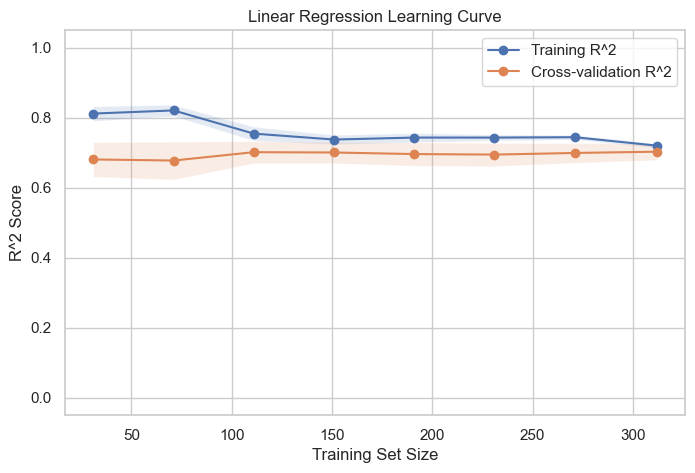

,Training Size,Mean Training R^2,Mean CV R^2
0,31,0.811716,0.680659
1,71,0.820692,0.677535
2,111,0.754419,0.701394
3,151,0.737486,0.700514
4,191,0.743136,0.696029
5,231,0.743137,0.694541
6,271,0.744158,0.699202
7,312,0.720110,0.702777


In [29]:
linear_learning_curve = plot_learning_curve(
    LinearRegression(),
    "Linear Regression",
    X_train_full,
    y_train_full,
    cv=KFold(n_splits=5, shuffle=True, random_state=1),
)

linear_learning_curve


The Linear Regression training and validation scores converge near 0.7 with a small gap.
This suggests relatively high bias or underfitting compared with stronger nonlinear models.


### Decision Tree Learning Curve


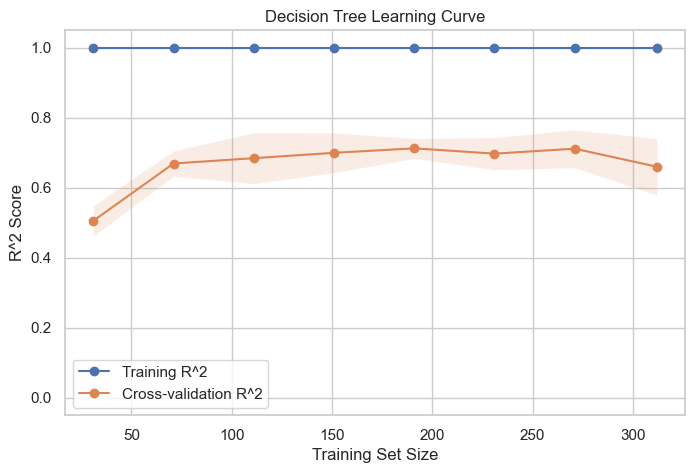

,Training Size,Mean Training R^2,Mean CV R^2
0,31,1.0,0.505384
1,71,1.0,0.669000
2,111,1.0,0.684333
3,151,1.0,0.699608
4,191,1.0,0.712377
5,231,1.0,0.697217
6,271,1.0,0.711371
7,312,1.0,0.659798


In [30]:
tree_learning_curve = plot_learning_curve(
    DecisionTreeRegressor(random_state=1),
    "Decision Tree",
    X_train_full,
    y_train_full,
    cv=KFold(n_splits=5, shuffle=True, random_state=1),
)

tree_learning_curve


The Decision Tree training score remains extremely high, while the validation score is clearly lower.
This is the learning-curve pattern of high variance and overfitting.


### Random Forest Learning Curve


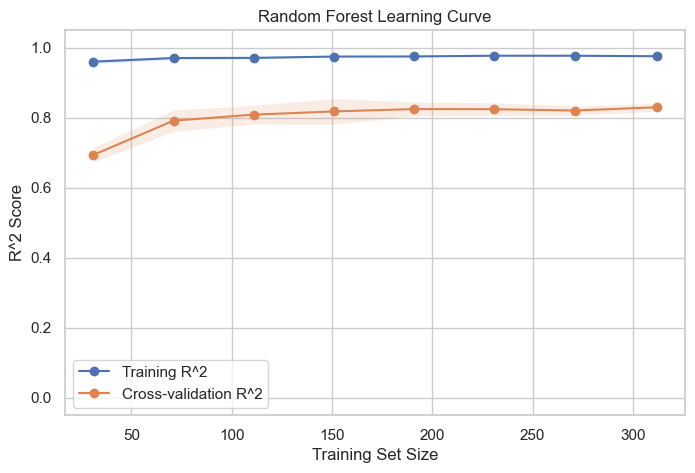

,Training Size,Mean Training R^2,Mean CV R^2
0,31,0.960014,0.693551
1,71,0.970442,0.791453
2,111,0.970828,0.808664
3,151,0.974636,0.817818
4,191,0.974878,0.824632
5,231,0.977035,0.824185
6,271,0.976958,0.820467
7,312,0.975498,0.829735


In [31]:
forest_learning_curve = plot_learning_curve(
    RandomForestRegressor(n_estimators=100, random_state=1),
    "Random Forest",
    X_train_full,
    y_train_full,
    cv=KFold(n_splits=5, shuffle=True, random_state=1),
)

forest_learning_curve


The Random Forest keeps a high training score and reaches a stronger validation score than the single Decision Tree.
The gap is smaller than the unrestricted tree, so the model generalizes better.


## Question 4 - Learning the Data

Choose one learning curve and describe what happens as more training points are added. Would more training points benefit the model?

### Answer
I chose the unrestricted Decision Tree learning curve, where `max_depth=None`.
For the unrestricted Decision Tree learning curve, the training score stays near 1.0 as more training points are added.
The cross-validation score improves at first, but it remains much lower than the training score and eventually plateaus or fluctuates.

More data helped initially, but after a point the improvements became small while the train-validation gap remained.
Therefore, additional data alone is unlikely to fully solve the overfitting problem.
Controlling model complexity is also necessary.


## 12. Bias vs Variance / Decision Tree Complexity

The next experiment changes only `max_depth` for the Decision Tree.
This makes the bias-variance tradeoff easier to see.


The instructor-provided `visuals.py` helper is used here to plot a Decision Tree validation curve across maximum depths. The manual table below complements this plot with exact scores from the train/validation split.


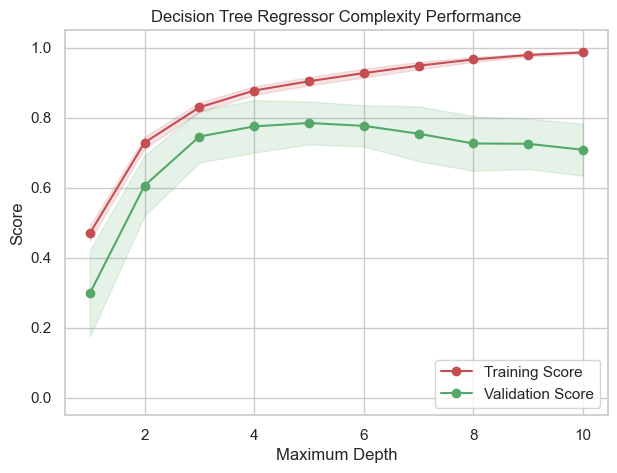

In [32]:
vs.ModelComplexity(X_train_full, y_train_full)


In [33]:
tree_depth_results = []

for depth in [1, 3, 5, 10]:
    depth_model = DecisionTreeRegressor(max_depth=depth, random_state=1)
    depth_model.fit(X_train, y_train)

    train_r2 = performance_metric(y_train, depth_model.predict(X_train))
    validation_r2 = performance_metric(y_val, depth_model.predict(X_val))

    tree_depth_results.append(
        {
            "max_depth": depth,
            "Train R^2": train_r2,
            "Validation R^2": validation_r2,
        }
    )

tree_depth_results = pd.DataFrame(tree_depth_results)
tree_depth_results


,max_depth,Train R^2,Validation R^2
0,1,0.460028,0.392261
1,3,0.821985,0.823457
2,5,0.900526,0.830690
3,10,0.987315,0.759609


`max_depth=1` has low training and validation scores, so it underfits and has high bias.
`max_depth=3` has a very good balance, with nearly equal train and validation scores.
`max_depth=5` has the highest validation score on this particular validation split.
`max_depth=10` has a very high training score but a clearly lower validation score, which indicates high variance and overfitting.

The validation split suggests that a moderate depth works best, but `max_depth=5` should not be treated as globally optimal yet because this is only one split.


## Question 5 - Bias-Variance Tradeoff

When the model is trained with a maximum depth of 1, does it suffer from high bias or high variance?
How about when it is trained with a maximum depth of 10?

### Answer

With `max_depth=1`, the model suffers from high bias and underfitting.
The evidence is that both the training and validation R^2 scores are low.

With `max_depth=10`, the model suffers from high variance and overfitting.
The evidence is that the training R^2 is very high, but the validation R^2 is clearly lower.


## Question 6 - Best-Guess Optimal Model

Which maximum depth do you think results in a model that best generalizes to unseen data?



### Answer

My preliminary best guess is `max_depth=5` because it achieved the highest
validation R^2 on the current validation split.

However, `max_depth=3` showed a smaller gap between training and validation
performance. Therefore, cross-validation will be used to make a more reliable
final decision.


## 13. Cross Validation

The next step uses 5-fold cross-validation on the development data, `X_train_full` and `y_train_full`.

In 5-fold cross-validation:

1. The development data is divided into 5 folds.
2. The model trains on 4 folds.
3. The model validates on the remaining fold.
4. The validation fold rotates until every fold has been used once.
5. The scores are averaged.


In [34]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1,
)


In [35]:
tree_depth_3 = DecisionTreeRegressor(max_depth=3, random_state=1)
scores_depth_3 = cross_val_score(
    tree_depth_3,
    X_train_full,
    y_train_full,
    cv=cv,
    scoring="r2",
)

print("max_depth = 3")
print("Fold Scores:", scores_depth_3)
print("Mean CV R^2:", scores_depth_3.mean())
print("Std:", scores_depth_3.std())


max_depth = 3
Fold Scores: [0.8234572  0.75184757 0.73757027 0.81882739 0.7946699 ]
Mean CV R^2: 0.7852744684118182
Std: 0.03482826782756319


In [36]:
tree_depth_5 = DecisionTreeRegressor(max_depth=5, random_state=1)
scores_depth_5 = cross_val_score(
    tree_depth_5,
    X_train_full,
    y_train_full,
    cv=cv,
    scoring="r2",
)

print("max_depth = 5")
print("Fold Scores:", scores_depth_5)
print("Mean CV R^2:", scores_depth_5.mean())
print("Std:", scores_depth_5.std())


max_depth = 5
Fold Scores: [0.83069044 0.71969115 0.75269168 0.81604545 0.76722844]
Mean CV R^2: 0.777269432735916
Std: 0.040932943119467886


In [37]:
cv_depth_comparison = pd.DataFrame(
    {
        "max_depth": [3, 5],
        "Mean CV R^2": [scores_depth_3.mean(), scores_depth_5.mean()],
        "Std": [scores_depth_3.std(), scores_depth_5.std()],
    }
)

cv_depth_comparison


,max_depth,Mean CV R^2,Std
0,3,0.785274,0.034828
1,5,0.777269,0.040933


The single validation split suggested `max_depth=5`.
However, 5-fold cross-validation slightly favors `max_depth=3`.
This shows why a single validation split can be noisy.


## Question 7 - Cross-Validation

What is k-fold cross-validation, and what benefit does it provide for grid search?

### Answer

K-fold cross-validation divides the development data into K folds.
The model is repeatedly trained on K-1 folds and validated on the remaining fold.
This repeats until each fold has served as the validation fold once.

For grid search, cross-validation gives a more reliable hyperparameter comparison because it is less dependent on one lucky or unlucky split.
It also uses the development data more efficiently and reports both the mean score and variability across folds.


## 14. Decision Tree Hyperparameter Tuning

GridSearchCV tests multiple hyperparameter values systematically.
Here, it searches `max_depth` values from 1 through 10 for a Decision Tree.


In [38]:
tree = DecisionTreeRegressor(random_state=1)

params = {
    "max_depth": range(1, 11),
}

grid_tree = GridSearchCV(
    estimator=tree,
    param_grid=params,
    scoring="r2",
    cv=cv,
)

grid_tree.fit(X_train_full, y_train_full)

best_tree = grid_tree.best_estimator_

print("Best max_depth:", grid_tree.best_params_["max_depth"])
print("Best CV R^2:", grid_tree.best_score_)
print("Best Model:", best_tree)


Best max_depth: 4
Best CV R^2: 0.7917096002331074
Best Model: DecisionTreeRegressor(max_depth=4, random_state=1)


GridSearchCV selected `max_depth=4`, which produced the best mean cross-validation score among the tested Decision Tree depths.


## Question 9 - Optimal Model

What maximum depth does the optimized Decision Tree have, and how does this compare with the guess in Question 6?

### Answer

The optimized Decision Tree has `max_depth=4`.

My preliminary guess in Question 6 was `max_depth=5`, so the optimized result
is very close to my original estimate. This supports the idea that a moderate
tree depth provides the best balance between bias and variance.


## 15. Random Forest Cross Validation

The Random Forest is now evaluated with the same 5-fold cross-validation setup.


In [39]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=1,
)

scores_rf = cross_val_score(
    rf_model,
    X_train_full,
    y_train_full,
    cv=cv,
    scoring="r2",
)

print("Fold Scores:", scores_rf)
print("Mean CV R^2:", scores_rf.mean())
print("Std:", scores_rf.std())


Fold Scores: [0.85210774 0.81419431 0.82544737 0.82961233 0.82475603]
Mean CV R^2: 0.8292235575848697
Std: 0.012521452207941066


The untuned Random Forest has a higher mean cross-validation score than the tuned Decision Tree and relatively low variability between folds.


## 16. Random Forest Hyperparameter Tuning

The Random Forest grid search tunes the number of trees, tree depth, and minimum split/leaf sizes.

`n_estimators` controls how many trees are built.
`max_depth` limits how deep each tree can grow.
`min_samples_split` controls the minimum samples required to split an internal node.
`min_samples_leaf` controls the minimum samples allowed in each leaf node.


In [40]:
rf = RandomForestRegressor(random_state=1)

params_rf = {
    "n_estimators": [100, 200],
    "max_depth": [None, 4, 6, 8],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=params_rf,
    scoring="r2",
    cv=cv,
    n_jobs=-1,
)

with parallel_backend("threading"):
    grid_rf.fit(X_train_full, y_train_full)

print("Best Parameters:")
print(grid_rf.best_params_)
print()
print("Best CV R^2:")
print(grid_rf.best_score_)
print()
print("Best Model:")
print(grid_rf.best_estimator_)


Best Parameters:
{'max_depth': 6, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}

Best CV R^2:
0.8400043332876791

Best Model:
RandomForestRegressor(max_depth=6, n_estimators=200, random_state=1)


The best Random Forest uses `max_depth=6`, `min_samples_leaf=1`, `min_samples_split=2`, and `n_estimators=200`.
Its mean cross-validation R^2 is about 0.840.


## 17. Model Selection

The final model is selected using cross-validation performance before inspecting the test set.


In [41]:
model_selection_summary = pd.DataFrame(
    {
        "Model": ["Tuned Decision Tree", "Tuned Random Forest"],
        "Mean CV R^2": [grid_tree.best_score_, grid_rf.best_score_],
    }
)

model_selection_summary


,Model,Mean CV R^2
0,Tuned Decision Tree,0.791710
1,Tuned Random Forest,0.840004


The tuned Random Forest is selected because it has the higher cross-validation score.
This decision is made before looking at the held-out test set.


## 18. Final Test Evaluation

The selected model is evaluated once on the untouched test set.
This gives the final estimate of generalization performance.


In [42]:
best_model = grid_rf.best_estimator_

test_pred = best_model.predict(X_test)
test_r2 = performance_metric(y_test, test_pred)
test_mae = mean_absolute_error(y_test, test_pred)
test_rmse = root_mean_squared_error(y_test, test_pred)

print(f"Final Random Forest Test R^2: {test_r2:.3f}")
print(f"Final Random Forest Test MAE: ${test_mae:,.2f}")
print(f"Final Random Forest Test RMSE: ${test_rmse:,.2f}")


Final Random Forest Test R^2: 0.829
Final Random Forest Test MAE: $48,555.72
Final Random Forest Test RMSE: $68,146.87


The tuned Random Forest has cross-validation R^2 around 0.840 and test R^2 around 0.829.
The difference is small, about 0.011, which supports good generalization.

R^2 measures explained variation.
MAE and RMSE express prediction error in house-price units, making the error easier to interpret.
These final test metrics are reported only after model selection and are not used to tune the model.


In [43]:
tree_test_pred = best_tree.predict(X_test)
tree_test_r2 = performance_metric(y_test, tree_test_pred)

print(f"Decision Tree Final Test R^2: {tree_test_r2:.3f}")


Decision Tree Final Test R^2: 0.778


The Decision Tree test score is shown only as a learning comparison.
The Random Forest had already been selected based on cross-validation before the test set was inspected.
The test set should not now be used repeatedly for new model or hyperparameter decisions.


## 19. Prediction on New Client Data

The following client data uses the values from the original project question table.


In [44]:
client_data = pd.DataFrame(
    {
        "RM": [5, 4, 8],
        "LSTAT": [17, 32, 3],
        "PTRATIO": [15, 22, 12],
    }
)

client_data


,RM,LSTAT,PTRATIO
0,5,17,15
1,4,32,22
2,8,3,12


In [45]:
client_predictions = best_model.predict(client_data)

client_results = client_data.copy()
client_results["Predicted MEDV"] = client_predictions
client_results["Predicted Price"] = client_results["Predicted MEDV"].map(lambda value: f"${value:,.2f}")

for i, price in enumerate(client_predictions, start=1):
    print(f"Client {i}: ${price:,.2f}")

print()
print(f"Observed MEDV range: ${prices.min():,.2f} to ${prices.max():,.2f}")

client_results


Client 1: $379,490.30
Client 2: $241,559.61
Client 3: $927,348.37

Observed MEDV range: $105,000.00 to $1,024,800.00


,RM,LSTAT,PTRATIO,Predicted MEDV,Predicted Price
0,5,17,15,379490.299069,"$379,490.30"
1,4,32,22,241559.606138,"$241,559.61"
2,8,3,12,927348.374242,"$927,348.37"


## Question 10 - Predicting Selling Prices

What price would you recommend each client sell the home at?
Do these prices seem reasonable given the respective features?

### Answer

Using the tuned Random Forest model, the predicted selling prices are:

| Client | Predicted Selling Price |
| --- | ---: |
| Client 1 | $379,490.30 |
| Client 2 | $241,559.61 |
| Client 3 | $927,348.37 |

Client 3 has the highest predicted value because it has the highest `RM`, the lowest `LSTAT`, and the lowest `PTRATIO`.
Client 2 has the lowest predicted value because it has the lowest `RM`, high `LSTAT`, and high `PTRATIO`.
Client 1 lies between them.

The predicted prices are within the observed `MEDV` data range, so they are reasonable relative to the dataset.


## 20. Final Project Conclusion

This project used 489 housing records and 3 predictors to model `MEDV`.
The dataset had no missing values or duplicated rows.
Statistical outliers were inspected and retained because they appeared plausible.
`LSTAT` had the strongest absolute correlation with `MEDV`.

Linear Regression was stable but underfit relative to nonlinear models.
An unrestricted Decision Tree overfit the training data.
The Random Forest generalized better, and GridSearchCV improved it further.

Model selection was based on cross-validation before touching the test set.
The tuned Random Forest achieved a CV R^2 of about 0.840 and a final test R^2 of about 0.829.
It also produced reasonable price estimates for the three client homes.


In [46]:
import joblib

joblib.dump(best_model, "boston_rf_model.joblib")

print("Model saved successfully.")

Model saved successfully.
